# IT1244 Group Project: CGM Device Failure Classification

This notebook runs the whole project in order: load the data, split it, analyse it, clean it, train the models and evaluate them. The code it calls is in `src/` (see README.md).

**Team:** Lim Su Ling, Ho Zi Yun Leanne, James Elliot Toh Zhiheng, Chng Lucas

**Task:** multi-class classification. Predict each report's `primary_category` (its IMDRF problem code, e.g. A07 Electrical, A09 Output, A13 Communication) from the free-text `event_description` of FDA MAUDE adverse event reports for continuous glucose monitors (CGMs).

**Model input:** `event_description` only. `brand_name`, `problem_terms`, `imdrf_top_categories` and `manufacturer_narrative` are used for analysis, never as model input.

| Section | Owner |
|---|---|
| 2. Train/test split | Lucas |
| 3. Dataset analysis | Leanne |
| 1. Loading, 4. Data cleaning | Suling, James |
| 5.1 TF-IDF + LR | James |
| 5.2 BiLSTM, 5.3 transformer | Suling |
| 6. Evaluation (incl. majority baseline) | Lucas |

## References and how we address their limitations

1. **Wang, Kang & Gong (2019), MEDINFO 2019.** *Generating a Health Information Technology Event Database from FDA MAUDE Reports.* TF-IDF models (LR, SVM, NB, RF) vs a CNN on 5,588 MAUDE reports; LR alone reached F1 0.859, the best ensemble 0.870.
   *Limitations and our approach:* their models ignore word context, the data contained duplicates, and it was artificially balanced. We use TF-IDF + LR only as our baseline and test whether models that read word order (BiLSTM) and context (transformer) do better; we keep duplicate descriptions on one side of the split; and we keep the real class imbalance, handling it with class weights and macro-F1.
2. **Li et al. (2024), Frontiers in Computational Neuroscience.** BiLSTM with attention for harm vs no-harm classification of 4,568 da Vinci surgical-robot MAUDE reports; F1 85.37, above plain BERT (78.61).
   *Limitations and our approach:* a small, single-device, binary dataset whose authors note performance on larger data is unvalidated. We test a BiLSTM (with attention) on ~380k CGM reports with a multi-class label, using dropout and early stopping to limit overfitting.
3. **Luschi, Nesi & Iadanza (2023), Heliyon.** Fine-tuned ClinicalBERT on 3,075 expert-labelled MAUDE reports to detect health-IT adverse events, with explainability.
   *Limitations and our approach:* a small dataset with no comparison against cheaper baselines. We fine-tune DistilBERT / Bio_ClinicalBERT on CGM reports and compare it directly with TF-IDF + LR and the BiLSTM on the same split and metrics, to see whether the extra compute is worth it.

Background: CGM failure modes in MAUDE, https://pmc.ncbi.nlm.nih.gov/articles/PMC11688675/

TODO: add the full links for references 1-3 from the proposal doc.

**Code attribution:** the transformer uses the Hugging Face `transformers` library and pretrained weights (`distilbert-base-uncased`, `emilyalsentzer/Bio_ClinicalBERT`).

## 0. Setup

1. Put the course CGM MAUDE file in `data/` (see `data/README.md`).
2. To **reproduce our results without training**, download the weights (see `links.txt`) into `weights/` and set `TRAIN = False`.
3. Run all cells top to bottom.

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from src import config
from src.analysis import eda
from src.data import cleaning, loading, splitting
from src.evaluation import cross_validation, metrics
from src.evaluation.baseline import MajorityBaseline
from src.helpers import device_info, get_device, set_seed
from src.models.bilstm import BiLSTMClassifier
from src.models.tfidf_lr import TfidfLR
from src.models.transformer import CLINICAL_BERT, DISTILBERT, TransformerClassifier


###for now, changed to false (eda)
TRAIN = False   # False: skip training and load the saved weights from weights/
RUN_CV = False  # 5-fold cross-validation to choose hyper-parameters (slow for the BiLSTM)

set_seed(config.SEED)
device = get_device()
config.WEIGHTS_DIR.mkdir(exist_ok=True)
print(device_info())

cpu


## 1. Load data (Suling, James)

In [2]:
df = loading.load_reports()
print(df.shape)
df.head()

NotImplementedError: TODO (Suling, James)

## 2. Train/test split (Lucas)

Stratified 80/20 split on `primary_category` with a fixed seed, with identical (template) descriptions kept on one side so test scores are not inflated. The test set is used **once**, in section 6.

In [3]:
train_df, test_df = splitting.split_train_test(df)
print(f"train {len(train_df):,} | test {len(test_df):,}")

NameError: name 'df' is not defined

## 3. Dataset analysis on the training set (Leanne)

### 3.1 Class counts
Informs: class weights, which rare classes to merge, and why macro-F1 is the main metric.

In [46]:
## Testing on the whole dataset

df = pd.read_csv("data/cgm_reports_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (379886, 10)


,mdr_report_key,brand_name,event_description,manufacturer_narrative,problem_codes,problem_terms,imdrf_top_categories,imdrf_top_category_names,primary_category,primary_category_name
0,21050673,DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)(4).,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem
1,21050676,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)(4).,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem
2,21050677,DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)94). 3004753838-2024-341468 WAS REP...,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem
3,21050678,DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)(4). B5: DESCRIBE EVENT OR PROBLEM ...,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem
4,21050679,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)(4).,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem


In [ ]:
import importlib
importlib.reload(eda)

<module 'src.analysis.eda' from 'c:\\Users\\leann\\OneDrive\\Desktop\\IT1244\\IT1244-Group-Project\\src\\analysis\\eda.py'>

,count,share_%
primary_category,,
A09,112521,29.619675
A13,102838,27.070753
A05,73061,19.232349
A16,47351,12.464529
A11,19912,5.241572
A04,10625,2.796892
A07,5606,1.475706
A27,4488,1.181407
A24,1330,0.350105


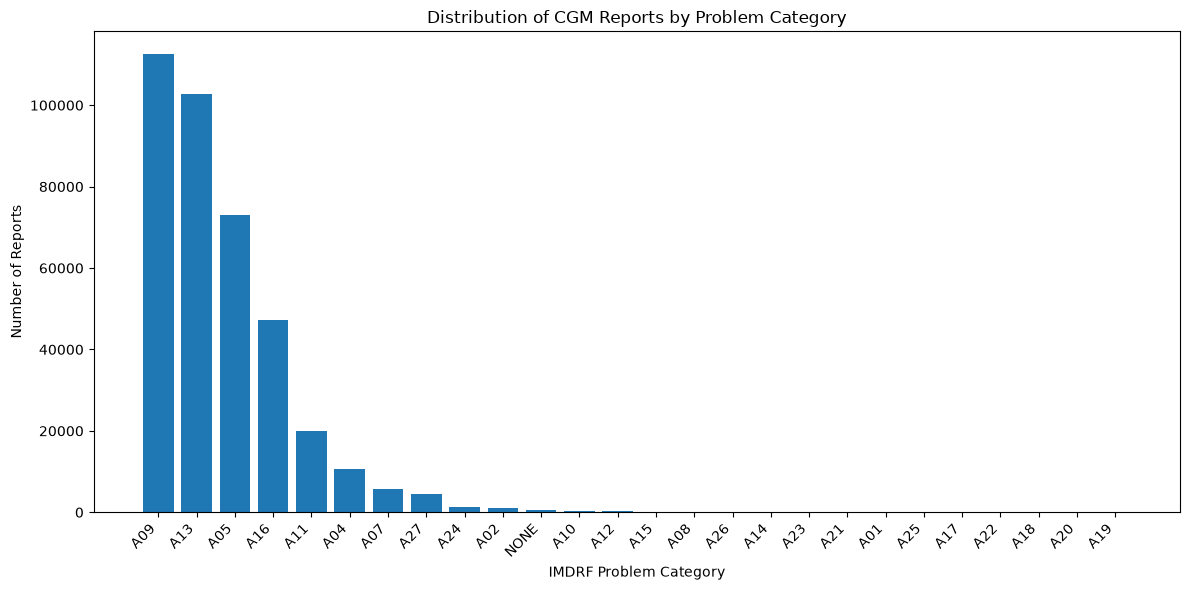

In [7]:
display(eda.class_counts(df["primary_category"]))

eda.plot_class_counts(
    df["primary_category"],
    save_as="class_counts.png"
)

# eda.plot_class_counts(train_df[config.LABEL_COL], save_as="class_counts.png")
# eda.class_counts(train_df[config.LABEL_COL])

In [ ]:
## Finding precise calculations
class_summary = eda.class_counts(df["primary_category"])

display(class_summary)

# Percentage of reports in the four largest categories
top_4_share = class_summary["share_%"].head(4).sum()

print(f"The top 4 most common classes account for {top_4_share:.2f}% of the labelled reports")

,count,share_%
primary_category,,
A09,112521,29.619675
A13,102838,27.070753
A05,73061,19.232349
A16,47351,12.464529
A11,19912,5.241572
A04,10625,2.796892
A07,5606,1.475706
A27,4488,1.181407
A24,1330,0.350105


The top 4 most common classes account for 88.39% of the labelled reports


In [ ]:
## Identifying rare classes
# Classes with fewer than five examples cannot be represented in all five validation folds.

# Classes with fewer than 5 reports
rare_classes = class_summary[class_summary["count"] < 5]

display(rare_classes)

print("Number of rare classes:", len(rare_classes))

,count,share_%
primary_category,,
A17,2,0.000526
A22,1,0.000263
A18,1,0.000263
A20,1,0.000263
A19,1,0.000263


Number of rare classes: 5


#### Observations
The distribution of CGM adverse event reports across IMDRF problem categories exhibits substantial class imbalance. Categories A09, A13, A05 and A16 account for the majority of reports, whereas several categories, including A17, A18 A19, A20 and A22, are extremely underrepresented, each containing less than 5 reports. This indicates a highly uneven distribution of classification labels.
There is also a category labelled NONE, which we will need to investigate whether NONE is a legitimate dataset label or not.


#### Interpretation
These class imbalances present several challenges for our supervised machine learning model. Models trained on this dataset will learn patterns that are associated with the frequently occurring categories more effectively as compared to those associated with minority categories. Consequently, models may demonstrate higher overall classification accuracy, but may perform poorly on less frequently reported problems.  
Furthermore, categories containing very few reports will provide insufficient examples for reliable model training and evaluation. This will complicate stratified data splitting and our five-fold cross-validation.


#### Implications for Model Development
In order to address such issues, our project will investigate class weighting and the appropriate handling of rare categories. Any merging of categories done will be consistent with the IMDRF taxonomy and the project’s classification requirements.


#### Evaluation Metric
Given the substantial class imbalance, we chose macro-F1 as the selected primary evaluation metric as it assigns equal importance to each class, regardless of its frequency. This ensures that poor performance on the minority categories is not obscured by the strong performance on the majority categories, allowing for a more balanced assessment of classification performance across the different IMDRF problem categories.



### 3.2 Text length
Informs: the maximum input length for the BiLSTM and transformer.

In [ ]:
display(eda.length_percentiles(df[config.TEXT_COL]))

p50     59.0
p90    107.0
p95    158.0
p99    249.0
Name: event_description, dtype: float64

##### Interpretation of percentiles
The results present that 50% of reports contain approximately 59 words or fewer, 90% contain approximately 107 words or fewer, 95% with 158 words or fewer and 99% containing approximately 249 words or fewer.
These suggest that choosing a maximum input length of approximately 160 words would preserve complete descriptions for about 95% of reports, while 256 words would preserve complete descriptions for at least 99%.


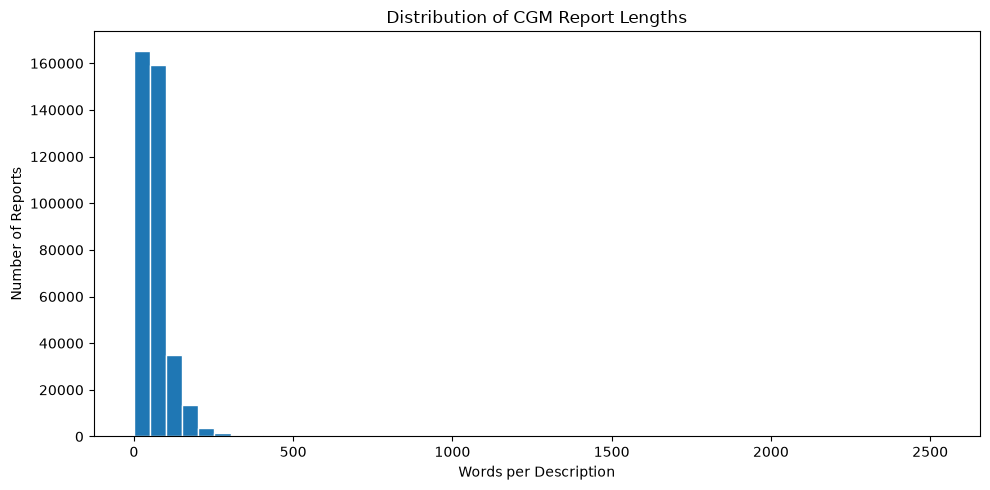

In [ ]:
eda.plot_length_hist(df[config.TEXT_COL], save_as="length_hist.png")

##### Interpretation of histogram

The plot is highly right-skewed, showing that most reports are concentrated at relatively low word counts, while a small number extend into the much longer tail. This is consistent with the percentile results, with the median of 59 words and the 99th percentile of 249 words.

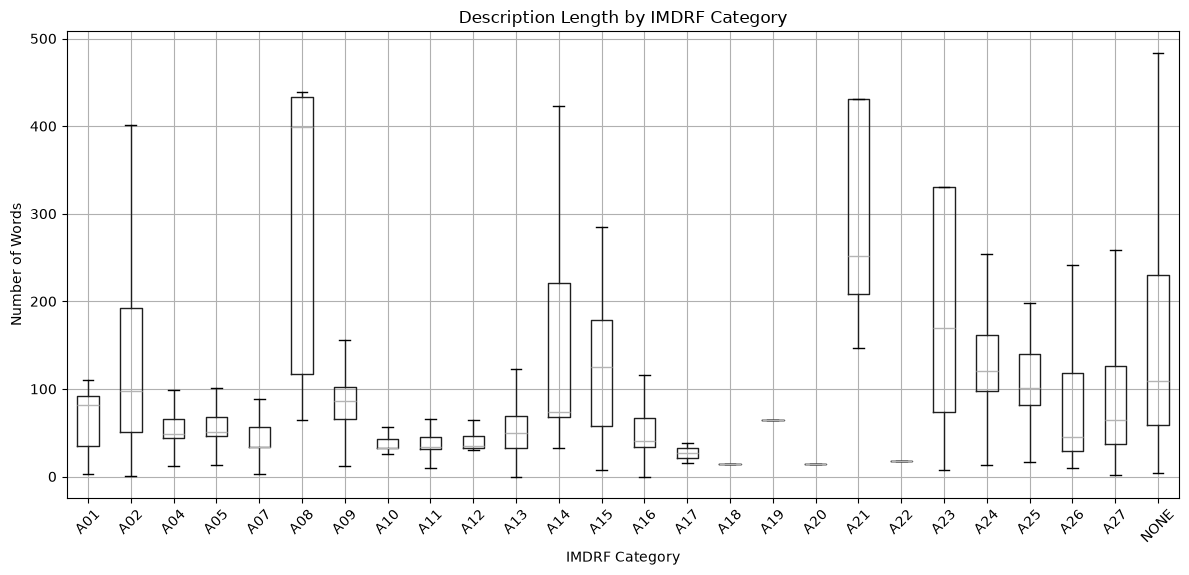

In [ ]:
eda.plot_length_by_class(df, save_as="length_by_class.png")

##### Interpretation of box plot
The box plots show how the description lengths differ across problem categories.
The plot suggests that categories such as A08, A21 and A23 contain some relatively long description or show substantial variation in report lengths. Meanwhile, categories like A10, A11, A12, and A17 have relatively short descriptions.
Using the same maximum input length for every category may disproportionately truncate reports from categories with longer descriptions. With our earlier class-count analysis in Section 3.1, it showed that several categories contained very few reports, thus apparent differences in the boxplots for the rare categories may be driven by the only one or two observations and should not be treated as reliable population patterns.


These graphical data brings about some implications that we would have to consider.

In [ ]:
## Determining how much text different input lengths can retain

# Calculate word counts for each description
word_lengths = (
    df[config.TEXT_COL]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Compare possible maximum input lengths
max_lengths = [64, 128, 256, 384, 512]

results = []

for length in max_lengths:

    retained = (word_lengths <= length).mean() * 100
    truncated = (word_lengths > length).mean() * 100

    results.append({
        "Max Length": length,
        "Reports Fully Retained (%)": round(retained, 2),
        "Reports Requiring Truncation (%)": round(truncated, 2)
    })

length_comparison = pd.DataFrame(results)

display(length_comparison)

,Max Length,Reports Fully Retained (%),Reports Requiring Truncation (%)
0,64,52.75,47.25
1,128,93.20,6.80
2,256,99.09,0.91
3,384,99.73,0.27
4,512,99.89,0.11


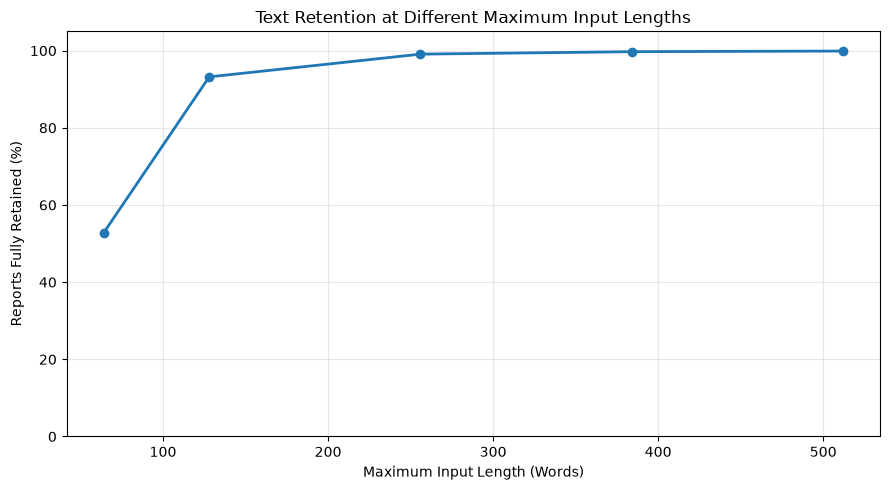

In [ ]:
## Visualising the input length trade-off

plt.figure(figsize=(9, 5))

plt.plot(
    length_comparison["Max Length"],
    length_comparison["Reports Fully Retained (%)"],
    marker="o",
    linewidth=2
)

plt.xlabel("Maximum Input Length (Words)")
plt.ylabel("Reports Fully Retained (%)")
plt.title("Text Retention at Different Maximum Input Lengths")

plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    config.FIGURES_DIR / "length_retention.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#### Observations
The analysis of text retention at different maximum input lengths reveals that increasing the sequence length substantially improves the proportion of CGM event descriptions that can be retained without truncation.

At 64 words, only 52.75% of reports can be fully retained. This means that 47.25% would require transaction, thus potentially removing information relevant to classifying CGM device problems. Therefore having 64 words is unlikely to be an appropriate maximum input length without further evidence. . Increasing the limit to 128 words raises this proportion to 93.20%, while a maximum length of 256 words accommodates 99.09% of reports. Increasing to anything beyond 256 words only provides diminishing returns. For example, increasing from 256 to 512 words would lead to an improvement of only 99.98%-99.09%=0.80%.
The text-retention curve demonstrates the similar plateau beyond approximately 256 words.

#### Interpretation
The findings highlight the trade-off between information retention and computational efficiency. 
Selecting a shorter maximum input length would reduce the computational requirements, but it may result in the truncation of longer descriptions, potentially removing contextual information that is important for a more accurate classification. 
Conversely, selecting an excessively long maximum input length would increase memory consumption and computational overhead, while only providing relatively small improvements in text retention.
Increasing beyond 256 words may not be computationally justified unless the additional information contributes meaningfully to the classification performance. 

#### Implications for Model Development
##### BiLSTM:
Based on the observed word-length distribution, we will investigate the maximum sequence lengths of128 and 256 tokens. While 128 only accommodates 93.20% of description, and increasing the limit to 256 words accommodate 99.09%, our final choice of maximum sequence length will be determined by balancing computational efficiency, text retention and cross-validation performance. 

##### Transformer:
Since DistilBERT and Bio_ClinicalBERT employ subword tokenisation, the word-length distribution alone is insufficient to determine the optimal maximum input length. 
Thus, the actual token-length distribution will be examined using the selected transformer’s tokeniser. Candidate lengths will subsequently be evaluated based on text retention, computational requirement and classification performance. 

### 3.3 Empty or very short descriptions
Informs: whether cleaning drops these reports or keeps them.

In [ ]:
eda.short_description_summary(df[config.TEXT_COL])

,reports,share_%
threshold,,
<= 0 words,4,0.001053
<= 3 words,48,0.012635
<= 5 words,74,0.019480
<= 10 words,123,0.032378


In [ ]:
# Calculate word counts
word_lengths = (
    df[config.TEXT_COL]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Count descriptions by length
empty_reports = (word_lengths == 0).sum()
very_short_reports = ((word_lengths >= 1) & (word_lengths <= 3)).sum()
short_reports = ((word_lengths >= 4) & (word_lengths <= 10)).sum()

print("Empty descriptions:", empty_reports)
print("1–3 words:", very_short_reports)
print("4–10 words:", short_reports)

Empty descriptions: 4
1–3 words: 44
4–10 words: 75


##### Observations:
Only 4 reports (0.0011%) contain empty descriptions, while 48 reports (0.0126%) contain three words or fewer. Furthermore, only 123 reports (0.0324%) contain ten words or fewer.

The results show that only 0.0324% of reports contain 10 words or fewer. Therefore, short descriptions represent a negligible proportion of our dataset.

In [ ]:
# Extract reports containing 1–3 words
very_short_df = df[
    (word_lengths >= 1) & (word_lengths <= 3)
]

# Display examples
display(
    very_short_df[
        [config.TEXT_COL, config.LABEL_COL]
    ].head(20)
)

,event_description,primary_category
7759,EARLY SENSOR EXPIRATION.,A16
8696,SIGNAL LOSS.,A13
18979,SIGNAL LOSS.,A13
23125,PHYSICAL DAMAGE.,A27
26970,APPLICATOR DEPLOYMENT.,A04
29937,EARLY SENSOR EXPIRATION.,A16
32216,PHYSICAL DAMAGE.,A04
32500,SIGNAL LOSS.,A13
34632,ALERT/NOTIFICATION SETTINGS.,A16
36476,CGM ACCURACY,A09


#### Observations:
As we examine the non-empty short descriptions, several reports were found to contain potentially information keywords such as “SIGNAL LOSS”, “EARLY SENSOR EXPIRATION" and “CGM ACCURACY”. Such keywords indicate the nature of the reported problems.
There is also the issue of ambiguity. For example, the description “PHYSICAL DAMAGE” is found to be associated with two different IMDRF categories, A04 and A27.


#### Interpretation:
The low proportion of empty and short descriptions suggest that missing textual information is not significant in terms of prevalence. Nonetheless, empty descriptions provide no usable textual features for classification, and may introduce noise into the training process.
Conversely, non-empty short descriptions may still contain highly informative terms associated with specific CGM problem categories. Removing them could result in unnecessary information loss. 
Identical descriptions associated with different labels may also lead to classification challenges, as our models rely exclusively on textual information to predict the primary category.

#### Implications for Model Development:
With these findings, we will consider removing the 4 empty reports and retain the non-empty short descriptions. Any further filtering will be considered based on the information content of the descriptions and its implications for model performance. 
In addition, we will also investigate reports with identical descriptions but different labels during the next duplicate analysis to identify any potential inconsistencies in the classification labels.


### 3.4 Duplicate (template) descriptions

In [9]:
duplicate_stats, top_templates = eda.duplicate_summary(df)
display(duplicate_stats, top_templates)

reports                                379886
reports with non-empty descriptions    379882
unique descriptions                     71174
duplicate texts                         10338
reports in duplicate groups            319046
duplicate texts with >1 label             701
dtype: int64

,count,labels
text,,
IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION. THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,27007,"{'A13': 26991, 'A09': 7, 'A05': 5, 'A16': 2, '..."
IT WAS REPORTED THAT A DETACHED OR MISSING SENSOR WIRE OCCURRED. THE SENSOR WAS INSERTED INTO THE ARM ON (B)(6) 2025. NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION. THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,25244,"{'A05': 25173, 'A04': 36, 'A12': 11, 'A16': 9,..."
IT WAS REPORTED THAT SIGNAL LOSS OCCURRED. PERFORMANCE DATA WAS REVIEWED. THE ALLEGATION WAS CONFIRMED DUE TO THE FINDING OF SIGNAL LOSS OVER AN HOUR WITHIN THE INVESTIGATION WINDOW. THE PROBABLE CAUSE WAS THE TRANSMITTER AND APP WERE UNABLE TO ESTABLISH A CONNECTION. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,9700,"{'A13': 9693, 'A05': 2, 'A11': 2, 'A09': 1, 'A..."
IT WAS REPORTED THAT A TRANSMITTER BATTERY ISSUE OCCURRED. NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION. THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,9179,"{'A09': 9105, 'A13': 63, 'A27': 7, 'NONE': 1, ..."
IT WAS REPORTED THAT AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) AND THE BLOOD GLUCOSE (BG) METER OCCURRED. THE SENSOR WAS INSERTED INTO THE ARM ON (B)(6) 2025. DATA WAS EVALUATED AND THE ALLEGATION WAS UNDETERMINED. THE PROBABLE CAUSE COULD NOT BE DETERMINED VIA DATA. THE REPORTED GLUCOSE VALUES FALL WITHIN THE D ZONE OF THE PARKES ERROR GRID. THE DATA INVESTIGATION DID NOT FIND BLOOD GLUCOSE CALIBRATION VALUES TO COMPARE TO CGM VALUES DURING THE REPORTED SENSOR SESSION OR THE CALIBRATIONS DURING THE REPORTED SENSOR SESSION WERE IN ACCURATE RANGE PER DEVICE SPECIFICATIONS. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,8084,"{'A09': 8073, 'A05': 11}"
IT WAS REPORTED THAT SIGNAL LOSS OCCURRED. PERFORMANCE DATA WAS REVIEWED. THE ALLEGATION WAS CONFIRMED DUE TO THE FINDING OF SIGNAL LOSS OVER AN HOUR WITHIN THE INVESTIGATION WINDOW. THE PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,7388,"{'A13': 7385, 'A11': 2, 'A16': 1}"
IT WAS REPORTED THAT A DEXCOM APP CRASH OCCURRED. DATA WAS EVALUATED AND THE ALLEGATION WAS CONFIRMED. THE PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,7328,"{'A11': 7244, 'A13': 58, 'A16': 24, 'A09': 1, ..."
IT WAS REPORTED THAT AN ALERT/NOTIFICATION SETTINGS ISSUE OCCURRED. NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION. THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,6493,"{'A16': 6463, 'A27': 12, 'A11': 7, 'A09': 4, '..."
"IT WAS REPORTED THAT A NO READINGS/ SENSOR ERROR/ BRIEF SENSOR ISSUE OCCURRED. PERFORMANCE DATA WAS REVIEWED. NO READINGS/ SENSOR ERROR/ BRIEF SENSOR ISSUE WAS NOT FOUND WITHIN THE INVESTIGATION WINDOW. THE ALLEGATION WAS NOT CONFIRMED. HOWEVER, SIGNAL LOSS OVER AN HOUR WAS FOUND IN CONNECTION TO THE REPORTED ALLEGATION. THE PROBABLE CAUSE OF THE SIGNAL LOSS WAS DETERMINED TO BE THE TRANSMITTER AND APP WERE UNABLE TO ESTABLISH A CONNECTION. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.",5754,"{'A13': 5753, 'A16': 1}"


In [12]:
## Percentage of duplicate results

# Total reports with non-empty descriptions
total_reports = duplicate_stats[
    "reports with non-empty descriptions"
]

# Number of reports belonging to duplicate groups
duplicate_reports = duplicate_stats[
    "reports in duplicate groups"
]

# Percentage of reports in duplicate groups
duplicate_percentage = duplicate_reports / total_reports * 100

print(f"Reports in duplicate groups: {duplicate_reports:,}")
print(f"Percentage in duplicate groups: {duplicate_percentage:.2f}%")

Reports in duplicate groups: 319,046
Percentage in duplicate groups: 83.99%


##### Observations:
The results reveal a large amount of duplicates within the CGM dataset. Of the 379,882 non-empty reports, 319,046 (83.99%) belong to duplicate groups. Furthermore, 10,338 distinct descriptions appear more than once, which suggests a substantial reuse of standardised reporting templates.
Additionally, 701 unique descriptions were associated with two or more primary IMDRF categories. These descriptions appear in 226,238 reports, representing about 59.55% of non-empty descriptions. 

In [18]:
# Prepare descriptions and labels
temp = df[[config.TEXT_COL, config.LABEL_COL]].copy()

temp["clean_text"] = (
    temp[config.TEXT_COL]
    .fillna("")
    .astype(str)
    .str.strip()
)

temp = temp[temp["clean_text"] != ""]

# Counting distinct labels per description
label_counts = (
    temp.groupby("clean_text")[config.LABEL_COL]
    .nunique(dropna=False)
)

# Find descriptions with conflicting labels
conflicting_texts = label_counts[label_counts > 1].index

# Find reports using those descriptions
conflicting_reports = temp[
    temp["clean_text"].isin(conflicting_texts)
]

print("Descriptions with conflicting labels:", len(conflicting_texts))

print("Reports affected:", len(conflicting_reports))

print(
    "Percentage of non-empty reports affected:",
    round(len(conflicting_reports) / len(temp) * 100, 2),
    "%"
)

# Number of reports for each description-label combination
label_distribution = (
    temp.groupby(["clean_text", config.LABEL_COL],
                 dropna=False)
    .size()
    .reset_index(name="count")
)

# Total reports for each unique description
total_per_text = (
    label_distribution.groupby("clean_text")["count"]
    .sum()
)

# Most frequent label count for each description
majority_per_text = (
    label_distribution.groupby("clean_text")["count"]
    .max()
)

# Reports with a label different from the majority label
minority_reports = (
    total_per_text - majority_per_text
).sum()

print("Reports differing from majority label:", minority_reports)

print(
    "Percentage of non-empty reports:",
    round(minority_reports / len(temp) * 100, 2),
    "%"
)

Descriptions with conflicting labels: 701
Reports affected: 226238
Percentage of non-empty reports affected: 59.55 %
Reports differing from majority label: 2401
Percentage of non-empty reports: 0.63 %


##### Observations:
Further analysis has revealed that only 2,401 reports (about 0.63%) have labels differing from the most frequently assigned label for their identical description. This suggests that most reports within these conflicting-label groups share a dominant classification label despite the presence of some disagreements.

#### Interpretation:
The large amount of duplicate description presents a significant risk of data leakage. If identical descriptions appear in both the training and test sets, the model may recognise previously encountered text rather than to generalise to unseen descriptions, The evaluation performance like macro-F1 may be overestimated as a result. 
Descriptions associated with multiple labels may also introduce ambiguity into the classification task. Since our models rely solely on event_description as input, they are not able to distinguish reports containing identical text but assigned different primary categories. 
Nonetheless, the relatively small proportion of reports (0.63%) differing from their description’s majority label suggest that disagreements are limited at the overall dataset level. Such differences may have come from unavailable contextual information in the descriptions. This does not necessarily indicate incorrect labeling. 

#### Implications for Model Development:
To minimise data leakage, our project will adopt a group-aware train-test splitting strategy to ensure that identical descriptions remain within the same partition. We will also consider group-aware cross-validation to prevent identical descriptions from appearing in both training and validation folds.
We will also investigate the impact of conflicting labels, particularly on minority categories. We will consider whether additional handling is justified based on their prevalence, potential classification ambiguity and validation performance, rather than just removing or relabelling these reports.
These measures aim to improve the reliability of model evaluation and provide a more meaningful assessment of the three models’ ability to generalise to unseen CGM reports. 


### 3.5 Reports by brand
Checks whether failure types and report style (templated vs free text) differ by brand.

In [32]:
brand_results = eda.brand_summary(df)

# Calculate share of total reports
brand_results["share_%"] = (
    brand_results["reports"] / len(df) * 100
)

# Select the 5 brands with the most reports
top5_summary = brand_results.head(5)

display(top5_summary.round(2))

,reports,duplicate_%,median_words,share_%
brand,,,,
DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,250723,88.84,55.0,66.00
DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,96415,90.84,50.0,25.38
FREESTYLE LIBRE 3 PLUS,8886,29.98,86.0,2.34
FREESTYLE LIBRE 2 PLUS,7105,2.60,112.0,1.87
FREESTYLE LIBRE 3,6246,8.26,158.0,1.64


##### Observations:
Dexcom G7 and G6 together account for 347,138 reports, approximately 91.38% of our entire dataset.
Dexcom reports are also much more repetitive, with G7 having 88.84% and G6 with 90.84% of reports belonging to repeated-description groups within the brand. This suggests a greater reuse of standardised descriptions among Dexcom reports than among the listed FreeStyle Libre products.

In [33]:
## Comparing problem catergories across the top 5 brands

# Select the top 5 brand-name entries
top5_brands = top5_summary.index

top5_df = df[
    df["brand_name"].isin(top5_brands)
].copy()

# Calculate percentage distribution within each brand
brand_class_share = pd.crosstab(
    brand_df["brand_name"],
    brand_df["category"],
    normalize="index"
) * 100

# Display the percentage table
display(brand_class_share.round(2))

category,A04,A05,A07,A09,A11,A13,A16,A27,Other
brand_name,,,,,,,,,
DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,0.75,2.85,0.91,39.94,4.23,29.95,20.23,0.85,0.30
DEXCOM G6 GLUCOSE PROGRAM CONTINUOUS GLUCOSE MONITORING SYSTEM,0.00,0.00,0.03,45.82,0.00,53.66,0.30,0.16,0.03
DEXCOM G7,3.09,0.85,4.05,30.46,2.34,0.32,3.19,0.00,55.70
DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,3.90,27.95,1.81,18.50,6.29,28.79,10.94,1.45,0.37
FREESTYLE LIBRE 2 PLUS,0.04,0.82,0.13,95.34,0.01,0.04,0.69,0.00,2.93
FREESTYLE LIBRE 2 PLUS SENSOR,0.00,0.00,0.00,100.00,0.00,0.00,0.00,0.00,0.00
FREESTYLE LIBRE 3,0.14,0.93,0.83,89.03,0.11,0.00,2.08,0.00,6.87
FREESTYLE LIBRE 3 PLUS,0.05,0.60,0.26,94.22,0.02,0.00,0.66,0.00,4.20
LIBRE 2 PLUS SENSOR FREESTYLE,0.00,0.00,0.00,100.00,0.00,0.00,0.00,0.00,0.00


##### Observations:
The distribution of IMDRF problem categories varies significantly across the major product entries.

Category A09 accounts for 95.34%, 94.22% and 89.03% of reports for FreeStyle Libre 2 Plus, FreeStyle Libre 3 Plus and FreeStyle Libre 3, respectively. 

In contrast, Dexcom G7, A05 and A13 account for 27.95% and 28.79% of reports respectively, while A09 accounts for 18.50%, displaying a more varied category distribution. 



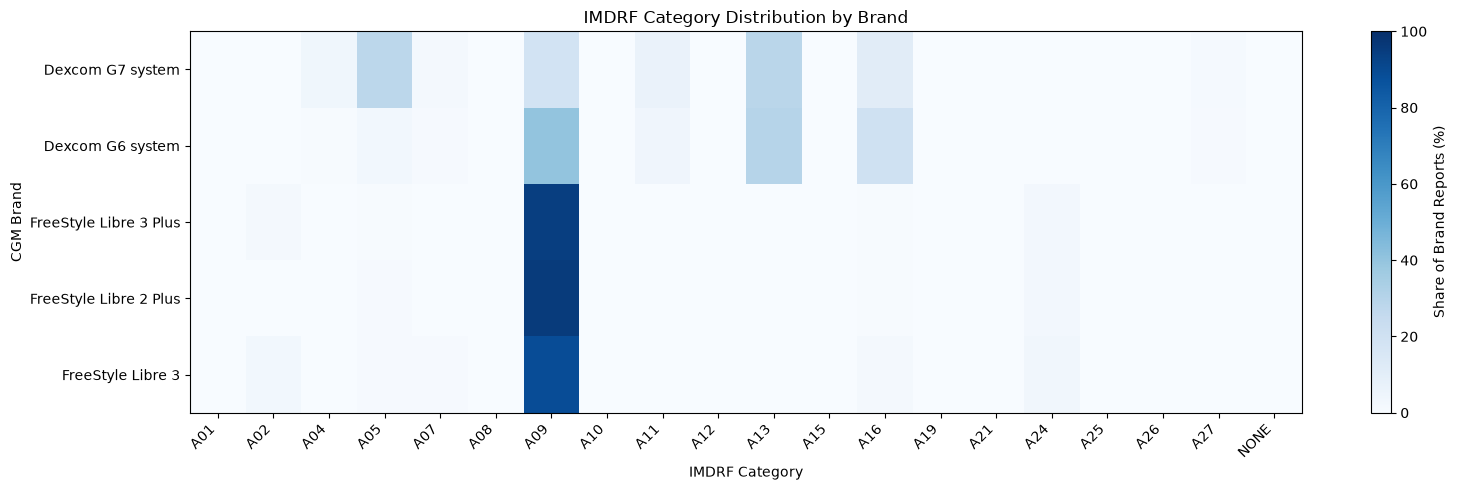

In [34]:
# Create a copy for plotting only
plot_df = top5_df.copy()

# Shorten product names for the graph
short_names = {
    "DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM": "Dexcom G7 system",
    "DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM": "Dexcom G6 system",
    "FREESTYLE LIBRE 3 PLUS": "FreeStyle Libre 3 Plus",
    "FREESTYLE LIBRE 2 PLUS": "FreeStyle Libre 2 Plus",
    "FREESTYLE LIBRE 3": "FreeStyle Libre 3"
}

plot_df["brand_name"] = (
    plot_df["brand_name"].replace(short_names)
)

# Plot using your existing EDA function
eda.plot_brand_by_class(
    plot_df,
    save_as="top5_brand_by_class.png"
)

In [35]:
## Verifying brand concentration

dexcom_reports = (
    top5_summary.loc[
        [
            "DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM",
            "DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM"
        ],
        "reports"
    ].sum()
)

dexcom_percentage = dexcom_reports / len(df) * 100

print(f"Dexcom G6 and G7 reports: {dexcom_reports:,}")
print(f"Share of dataset: {dexcom_percentage:.2f}%")

Dexcom G6 and G7 reports: 347,138
Share of dataset: 91.38%


##### Interpretation:
These findings suggest that both the distribution of reported problems and textual reporting patterns vary across CGM products.
The high concentration of reports among Dexcom products may cause classification models to learn linguistic patterns and category distribution associated with these products more extensively than those of less represented brands. 
In addition, the high duplication rates among Dexcom reports are consistent with greater reuse of standardised reporting templates. Conversely, the lower duplication rates among the listed FreeStyle Libre products suggest greater textual variation. 
These differences can affect model generalisation. Models may perform well on frequently repeated reporting patterns, and encounter greater difficulty when classifying less familiar descriptions from other products. 
However, these differences in IMDRF category distributions should not be interpreted as differences in the actual devices failure rates. Other factors like reporting practices and product usage may have influenced the number and nature of the submitted reports. 

#### Implications for Model Development:
##### 1. Brand-level evaluation:
Given the large differences in reporting patterns, our project should consider evaluating classification performances across sufficiently represented brands. Compering per-brand macro-F1 scores could help us identify whether overall model performance is disproportionately influenced by the dominant Dexcom reports.

##### 2. Prevention of data leakage:
The high prevalence of duplicated descriptions reinforces the need for group-aware train-test split and cross-validation. This ensures that identical descriptions do not appear in both training and evaluation partitions. 

##### 3. Generalisation across reporting styles:
The differences in description length and textual repetition suggest that models should be evaluated on descriptions with varying linguistic characteristics. This is particularly relevant when comparing TF-IDF + Logistic Regression, BiLSTM and transformer models.

##### 4. Brand-name consistency:
The dataset contains variations in product naming conventions, like "DEXCOM G7" and "DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM". These entries should be verified before any brand-name standardisation, to avoid incorrectly combining distinct products.
Although brand information will not be used as a predictive input, it may be retained for supplementary performance analysis. These measures aim to improve the reliability of our model evaluations and provide a more meaningful assessment of model generalisation.


### 3.6 Reports with more than one IMDRF category
Informs: evaluating single- and multi-category reports separately (section 6.4).

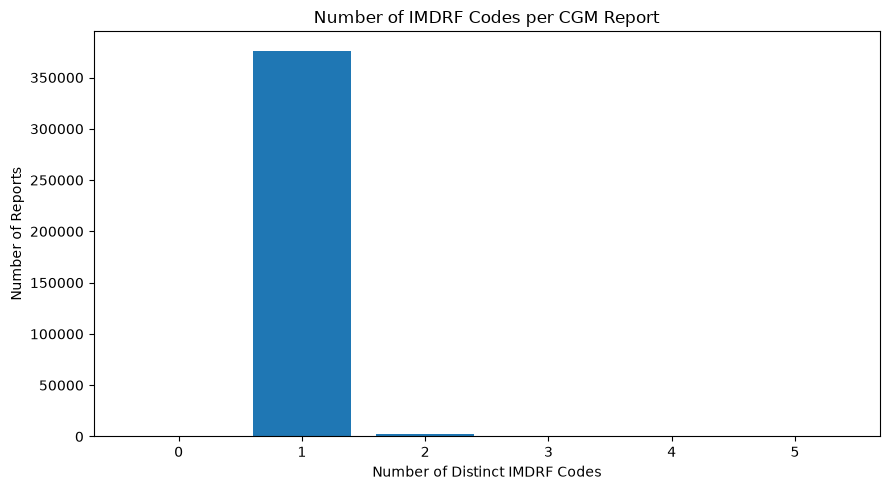

,Number of IMDRF Codes,reports,share_%
0,0,473,0.12
1,1,376233,99.04
2,2,2770,0.73
3,3,319,0.08
4,4,77,0.02
5,5,14,0.00


In [37]:
eda.plot_imdrf_code_counts(df[config.IMDRF_COL], save_as="imdrf_codes.png")


# Count distinct IMDRF codes for each report
code_counts = eda.count_imdrf_codes(
    df[config.IMDRF_COL]
)

# Create frequency table
code_summary = (
    code_counts.value_counts()
    .sort_index()
    .rename_axis("Number of IMDRF Codes")
    .reset_index(name="reports")
)

# Calculate percentage of total reports
code_summary["share_%"] = (
    code_summary["reports"] / len(df) * 100
)

display(code_summary.round(2))

##### Observations:
The results above reveal that a vast majority (99.04%) of CGM adverse event reports contain only one recognised IMDRF code. Only 3,180 reports (0.84%) contain two or more codes. 2,770 reports contain two codes, 319 contain three codes, 77 contain four codes, and only 14 contain five codes.
Additionally, 473 reports (0.12%) have no recognised IMDRF codes, requiring further investigation to determine whether this reflects missing information or limitations in code extraction.


In [38]:
## Comparing single-code vs multi-code reports

# Count reports by type
zero_codes = (code_counts == 0).sum()
single_code = (code_counts == 1).sum()
multi_code = (code_counts >= 2).sum()

# Display counts and percentages
comparison = pd.DataFrame({
    "Report Type": [
        "No recognised code",
        "Single-code",
        "Multi-code"
    ],
    "Reports": [
        zero_codes,
        single_code,
        multi_code
    ]
})

comparison["share_%"] = (
    comparison["Reports"] / len(df) * 100
)

display(comparison.round(2))

,Report Type,Reports,share_%
0,No recognised code,473,0.12
1,Single-code,376233,99.04
2,Multi-code,3180,0.84


#### Interpretation:
The substantial dominance of single-code reports suggests that most reports are associated with one coded problem category.
Reports containing multiple IMDRF codes may present additional classification challenges, as their descriptions could contain information associated with several device problems.

Since our models are designed to predict only one primary_category for each report, 
descriptions involving multiple problems may introduce ambiguity when determining the appropriate primary classification label.

Furthermore, given the small proportion of multi-code reports, the overall model performance may not adequately reflect classification performance on this subgroup. Nevertheless, whether multi-code reports are actually more challenging to classify remains to be determined through model evaluation.

#### Implications for Model Development:
To investigate whether classification performance differs between single-code and multi-code reports, our project will conduct supplementary evaluation on these two groups separately.

In **Section 6.4**, the macro-F1 scores of TF-IDF + Logistic Regression, BiLSTM and the fine-tuned transformer will be compared across single-code and multi-code reports using the held-out test set.

This analysis will help determine whether the presence of multiple reported problem categories is associated with differences in classification performance.
However, given the relatively small number of multi-code reports, subgroup results will be interpreted cautiously, particularly for categories with limited representation.

More importantly, our project will retain its original single-label classification objective, predicting primary_category solely from event_description. The number of IMDRF codes will be used only for supplementary evaluation rather than as an additional predictive feature.


### 3.7 Most frequent words and phrases per category
Informs: text-cleaning steps and the TF-IDF n-gram range.

In [41]:
ngram_results = eda.top_ngrams_per_class(df[config.TEXT_COL], df[config.LABEL_COL], k=15)
display(ngram_results)

,A01,A02,A04,A05,A07,A08,A09,A10,A11,A12,...,A19,A20,A21,A22,A23,A24,A25,A26,A27,NONE
0,device,sensors,reported,reported,reported,sensor,reported,reported,reported,reported,...,device,causing,app,consent,dexcom,patient,adc,patient,patient,dexcom
1,skin,no,sensor,sensor,no,failed,glucose,no,not,no,...,patient,causing minor,not,consent follow,g7,skin,information,no,reported,sensor
2,symptoms,dexcom,no,no,receiver,blood,no,not,no,data,...,power,correctly,use,device,sensors,no,received,information,no,sensors
3,dexcom,device,not,not,not,glucose,data,determined,data,determined,...,shut,correctly causing,problem,device ran,sensor,reaction,event,sensor,not,g7
4,removed,sensor,determined,product,product,g7,sensor,intervention,cause,probable cause,...,ago,did,sensor,did,device,sensor,no,not,determined,not
5,sensor,report,product,determined,injury,readings,values,intervention reported,probable,cause,...,adverse,did not,no,did not,not,skin reaction,report,reported,data,dexcom g7
6,arm,not,2025,2025,determined,sensors,not,medical,probable cause,probable,...,adverse signs,freestyle,people,follow,feel,reported,provided,provided,sensor,glucose
7,site,customer,broken,medical,medical,not,error,no injury,allegation,provided,...,collision device,freestyle libre,device,hcp,people,event,information provided,data,cause,blood
8,days,g7,medical,intervention,intervention,dexcom,injury,medical intervention,occurred,not,...,ago device,injury,product,hcp did,hand,2025,abbott,report,probable,cgm
9,monitoring,no report,occurred,medical intervention,medical intervention,low,grid,injury medical,determined,injury medical,...,called report,install,sensors,not,lot,experienced,customer,event,probable cause,readings


In [42]:
# Select the four major categories
major_classes = ["A09", "A13", "A05", "A16"]

# Keep categories present in the output
major_classes = [
    c for c in major_classes
    if c in ngram_results.columns
]

display(ngram_results[major_classes])

,A09,A13,A05,A16
0,reported,reported,reported,reported
1,glucose,loss,sensor,no
2,no,signal,no,not
3,data,signal loss,not,determined
4,sensor,no,product,medical
5,values,not,determined,injury
6,not,allegation,2025,intervention
7,error,data,medical,medical intervention
8,injury,occurred,intervention,intervention reported
9,grid,medical,medical intervention,no injury


In [43]:
# Create a copy for vocabulary analysis
unique_df = df.dropna(
    subset=[config.TEXT_COL, config.LABEL_COL]
).copy()

# Standardise surrounding whitespace
unique_df["_normalized_text"] = (
    unique_df[config.TEXT_COL]
    .astype(str)
    .str.strip()
)

# Exclude empty descriptions
unique_df = unique_df[
    unique_df["_normalized_text"] != ""
]

# Keep one occurrence of each description-label combination
unique_df = unique_df.drop_duplicates(
    subset=["_normalized_text", config.LABEL_COL]
)

# Generate top words/phrases without repeated combinations
unique_ngram_results = eda.top_ngrams_per_class(
    unique_df["_normalized_text"],
    unique_df[config.LABEL_COL],
    k=15
)

# Compare the major categories
display(
    pd.concat(
        {
            "All Reports": ngram_results[major_classes],
            "Unique Text-Label Pairs":
                unique_ngram_results.reindex(columns=major_classes)
        },
        axis=1
    )
)

All Reports                                               \
             A09                   A13                    A05   
0       reported              reported               reported   
1        glucose                  loss                 sensor   
2             no                signal                     no   
3           data           signal loss                    not   
4         sensor                    no                product   
5         values                   not             determined   
6            not            allegation                   2025   
7          error                  data                medical   
8         injury              occurred           intervention   
9           grid               medical   medical intervention   
10        parkes          intervention  intervention reported   
11    error grid                injury                 injury   
12  parkes error  medical intervention              no injury   
13          zone             no injury         injury medical   
14          fall        injury medical               occurred   

                          Unique Text-Label Pairs                        \
                      A16                     A09                   A13   
0                reported                reported              reported   
1                      no                 results                  loss   
2                     not                 glucose                signal   
3              determined                  sensor           signal loss   
4                 medical                customer                   not   
5                  injury                      dl                    no   
6            intervention                      mg            allegation   
7    medical intervention                   mg dl              occurred   
8   intervention reported                      no               medical   
9               no injury                  values          intervention   
10         injury medical                  device            determined   
11                   data                   error                injury   
12                 sensor                    grid  medical intervention   
13               occurred                  parkes             no injury   
14             allegation              error grid        injury medical   

                                                  
                      A05                    A16  
0                reported               reported  
1                  sensor                     no  
2                 product                    not  
3                     not             determined  
4                    2025                  alert  
5                      no                product  
6              determined                medical  
7                received               occurred  
8        product received                 injury  
9                 medical           intervention  
10           intervention              performed  
11   medical intervention   medical intervention  
12  intervention reported              no injury  
13                 injury  intervention reported  
14              no injury         injury medical

#### Observations:
The analysis of the 15 most frequent unigrams and bigrams across the four major IMDRF categories (A09, A13, A05 and A16) reveals differences in vocabulary patterns.

Certain categories contain terms associated with their reported device problems. For instance, A09 frequently includes terms such as "glucose", "values" and "error grid", while A13 contains communication-related expressions such as "signal", "loss" and "signal loss". Meanwhile, A05 frequently includes device-related terminology such as "sensor" and "product".

However, generic reporting terms such as "reported", "no", "not" and "medical intervention" also appear frequently across multiple categories, with "reported" being the most frequent term in all four categories. This suggests extensive use of standardised reporting language.

Furthermore, in the comparison of all reports against unique description-label combinations,  it reveals changes in vocabulary rankings, particularly for A09, where terms such as "results", "customer" and "mg dl" become more prominent after deduplication. On the other hand, expressions such as "signal loss" remain highly ranked within A13, indicating that certain problem-related phrases occur across distinct descriptions.

#### Interpretation:
These findings suggest that both individual words and multi-word expressions may provide useful information for distinguishing IMDRF problem categories.

In particular, bigrams such as "signal loss" and "error grid" capture more specific contextual information than their constituent words alone, potentially improving the ability of TF-IDF features to represent device-related problems.

However, the frequent occurrence of generic reporting terminology across several categories suggests that some words and phrases may provide limited discriminatory information. The changes observed after deduplication indicate that repeated reporting templates can influence vocabulary frequency rankings.

Nonetheless, high frequency does not necessarily imply predictive importance, and the usefulness of these terms must be assessed through model evaluation.

#### Implications for Model Development:
##### 1. TF-IDF n-gram selection:
Our project will investigate both unigram-only **(ngram_range=(1, 1))** and combined unigram-bigram **(ngram_range=(1, 2))** representations. Including bigrams can help to capture meaningful phrases associated with specific device problems. The final configuration will be selected based on the cross-validation macro-F1 performance.

##### 2. Text preprocessing:
The project will investigate whether generic reporting terms contribute useful information to classification. However, aggressive stop-word removal will be avoided initially, particularly for negation terms such as "no" and "not", which may alter the meaning of descriptions.

Additionally, domain-specific terminology and potentially informative multi-word expressions will be preserved during preprocessing.

##### 3. Influence of duplicate templates:
Given the high prevalence of duplicate descriptions identified in **Section 3.4**, the project will consider how repeated reporting language affects vocabulary distributions and model learning.

Group-aware splitting and cross-validation will be also used to reduce the risk of models achieving inflated evaluation performance through memorisation of repeated descriptions.
These measures aim to improve the quality of textual features and support a reliable comparison of TF-IDF + Logistic Regression, BiLSTM and transformer models.



## 4. Data cleaning (Suling, James)

Steps chosen from the analysis in section 3 (see `src/data/cleaning.py`). The same steps are applied to the training and test sets; rare classes are found from the training set only.

In [ ]:
train_df = cleaning.clean_reports(train_df)
test_df = cleaning.clean_reports(test_df)

rare_classes = cleaning.find_rare_classes(train_df[config.LABEL_COL])
train_df[config.LABEL_COL] = cleaning.merge_classes(train_df[config.LABEL_COL], rare_classes)
test_df[config.LABEL_COL] = cleaning.merge_classes(test_df[config.LABEL_COL], rare_classes)

X_train, y_train = train_df[config.TEXT_COL], train_df[config.LABEL_COL]
X_test, y_test = test_df[config.TEXT_COL], test_df[config.LABEL_COL]

# Cross-validation folds on the cleaned training set, shared by all models
folds = splitting.cv_folds(train_df)

# Max input length in words for the BiLSTM and transformer: long enough for 95% of reports
MAX_LEN = int(eda.length_percentiles(X_train)["p95"])
print("MAX_LEN =", MAX_LEN)

## 5. Models

Every model has the same methods (`src/interfaces.py`): `fit(texts, labels)`, `predict(texts)`, `predict_proba(texts)`, `save(path)` and `load(path)`. All use class weighting for the imbalance and the same split and folds.

### 5.1 TF-IDF + Logistic Regression (James)

Word/phrase counts weighted by TF-IDF, then logistic regression with balanced class weights. Cross-validated over the n-gram range and regularisation strength `C`.

In [ ]:
tfidf_path = config.WEIGHTS_DIR / "tfidf_lr.joblib"
tfidf_params = dict(ngram_range=(1, 2), C=1.0)  # used if cross-validation is skipped

if TRAIN and RUN_CV:
    tfidf_grid = [dict(ngram_range=(1, 1), C=1.0),
                  dict(ngram_range=(1, 2), C=1.0),
                  dict(ngram_range=(1, 2), C=10.0)]
    tfidf_cv, tfidf_params = cross_validation.grid_search(TfidfLR, tfidf_grid, X_train, y_train, folds)
    display(tfidf_cv)

if TRAIN:
    tfidf = TfidfLR(**tfidf_params).fit(X_train, y_train)
    tfidf.save(tfidf_path)
else:
    tfidf = TfidfLR.load(tfidf_path)

tfidf.top_features(k=10)  # compare with the phrases in section 3.7

### 5.2 Bidirectional LSTM (Suling)

Word embeddings → BiLSTM (reads the report in both directions) → attention → linear layer. Class-weighted loss, dropout, and early stopping on 10% of the training data (never the test set). Cross-validated over hidden size and dropout.

In [ ]:
bilstm_path = config.WEIGHTS_DIR / "bilstm.pt"

def make_bilstm(**params):
    return BiLSTMClassifier(max_len=MAX_LEN, epochs=10, patience=2, device=device, **params)

bilstm_params = dict(hidden_dim=128, dropout=0.3)  # used if cross-validation is skipped

if TRAIN and RUN_CV:
    bilstm_grid = [dict(hidden_dim=128, dropout=0.3),
                   dict(hidden_dim=256, dropout=0.3),
                   dict(hidden_dim=128, dropout=0.5)]
    bilstm_cv, bilstm_params = cross_validation.grid_search(make_bilstm, bilstm_grid, X_train, y_train, folds)
    display(bilstm_cv)

if TRAIN:
    bilstm = make_bilstm(**bilstm_params).fit(X_train, y_train)
    bilstm.save(bilstm_path)
    display(pd.DataFrame(bilstm.history_))
else:
    bilstm = BiLSTMClassifier.load(bilstm_path, device=device)

### 5.3 Fine-tuned transformer (Suling)

A pretrained transformer with a new classification layer, fine-tuned on our reports. It needs a GPU (e.g. Colab); otherwise train on a smaller stratified sample. Standard fine-tuning settings (learning rate 2e-5, up to 3 epochs, early stopping) instead of cross-validation, because each run is expensive.

In [ ]:
transformer_path = config.WEIGHTS_DIR / "transformer"
TRANSFORMER_MODEL = DISTILBERT       # or CLINICAL_BERT
TRANSFORMER_TRAIN_SAMPLES = 50_000   # stratified sample to save compute; None = all training data

if TRAIN:
    sample = train_df
    if TRANSFORMER_TRAIN_SAMPLES and TRANSFORMER_TRAIN_SAMPLES < len(train_df):
        sample, _ = train_test_split(train_df, train_size=TRANSFORMER_TRAIN_SAMPLES,
                                     stratify=train_df[config.LABEL_COL], random_state=config.SEED)

    transformer = TransformerClassifier(
        model_name=TRANSFORMER_MODEL,
        max_len=min(512, int(MAX_LEN * 1.3)),  # a word is ~1.3 sub-word tokens; 512 is the model limit
        device=device,
    ).fit(sample[config.TEXT_COL], sample[config.LABEL_COL])
    transformer.save(transformer_path)
    display(pd.DataFrame(transformer.history_))
else:
    transformer = TransformerClassifier.load(transformer_path, device=device)

## 6. Evaluation on the test set (Lucas)

The test set is used once, here. Main metric is **macro-F1** (every category counts equally, so a model cannot score well by ignoring rare failure types).

### 6.1 Overall comparison

The first row is the majority baseline (`src/evaluation/baseline.py`), which always predicts the most common training category. It is the minimum bar every model must beat, and its high accuracy but very low macro-F1 shows why macro-F1 is the main metric.

In [ ]:
baseline = MajorityBaseline().fit(X_train, y_train)

models = {"Majority baseline": baseline, "TF-IDF + LR": tfidf, "BiLSTM": bilstm,
          "Transformer": transformer}
predictions = {name: model.predict(X_test) for name, model in models.items()}

pd.DataFrame({name: metrics.scores(y_test, pred) for name, pred in predictions.items()}).T

### 6.2 Per-class results and confusion matrices

In [ ]:
for name, file_name in [("TF-IDF + LR", "confusion_tfidf.png"),
                        ("BiLSTM", "confusion_bilstm.png"),
                        ("Transformer", "confusion_transformer.png")]:
    print(name)
    display(metrics.per_class_report(y_test, predictions[name]))
    metrics.plot_confusion_matrix(y_test, predictions[name], title=name, save_as=file_name)

### 6.3 Macro-F1 by brand

In [ ]:
pd.DataFrame({name: metrics.macro_f1_by_group(y_test, pred, test_df[config.BRAND_COL])
              for name, pred in predictions.items()})

### 6.4 Macro-F1 on single- vs multi-category reports

In [ ]:
is_multi = eda.count_imdrf_codes(test_df[config.IMDRF_COL]) > 1
report_type = np.where(is_multi, "multi-category", "single-category")
pd.DataFrame({name: metrics.macro_f1_by_group(y_test, pred, report_type)
              for name, pred in predictions.items()})

### 6.5 Binary extension: defect vs not

Recall comes first: missing a real defect costs more than a false alarm. A model's defect probability is its total probability over the defect categories.

In [ ]:
DEFECT_CLASSES = []  # TODO (Lucas): the primary_category codes that count as a defect

if DEFECT_CLASSES:
    is_defect = y_test.isin(DEFECT_CLASSES).to_numpy().astype(int)
    binary_results = {}
    for name in ["TF-IDF + LR", "BiLSTM", "Transformer"]:
        model = models[name]
        defect_columns = np.isin(model.classes_, DEFECT_CLASSES)
        defect_probability = model.predict_proba(X_test)[:, defect_columns].sum(axis=1)
        binary_results[name] = metrics.binary_scores(is_defect, defect_probability)
    display(pd.DataFrame(binary_results).T)

### 6.6 Comparison with previous MAUDE studies

| Study | Data | Task | Best reported |
|---|---|---|---|
| Wang et al. 2019 | 5,588 MAUDE reports, balanced | binary (health-IT or not) | LR F1 0.859; SVM+LR+CNN F1 0.870 |
| Li et al. 2024 | 4,568 da Vinci reports | binary (harm or not) | BiLSTM-attention F1 85.37; BERT 78.61 |
| Luschi et al. 2023 | 3,075 labelled MAUDE reports | binary (health-IT or not) | fine-tuned ClinicalBERT |
| **Ours** | CGM MAUDE reports | multi-class IMDRF category | see 6.1 |

These studies used smaller datasets and binary labels, so the numbers are a rough reference, not a like-for-like comparison.

## 7. Discussion

TODO: which model is best and why (with evidence from 6.1-6.5), where models fail, comparison with human coders, and societal impact (privacy, fairness across brands, interpretability, jobs).